In [9]:
import json, re, time
import numpy as np
import requests
import matplotlib.pyplot as plt
from matplotlib.path import Path as MplPath
import astropy.units as u
from astropy.coordinates import SkyCoord, Distance
from astropy.time import Time
from astropy.io import fits
from astropy.wcs import WCS
from astropy.table import vstack
from astroquery.ipac.irsa import Irsa
from pyvo.dal import DALServiceError
from app.config import get_settings

cfg = get_settings()
TARGET = "eps Ind B"

# --- target position with proper motion (Sesame) ------------------------------------------
xml = requests.get(cfg.sesame_url + requests.utils.quote(TARGET), timeout=30).text
num = lambda p: (m := re.search(p, xml, re.S)) and float(m.group(1))
ra0, dec0 = num(r"<jradeg>([-\d.eE+]+)"), num(r"<jdedeg>([-\d.eE+]+)")
pmra, pmdec, plx = num(r"<pmRA>([-\d.eE+]+)"), num(r"<pmDE>([-\d.eE+]+)"), num(r"<plx>\s*<v>([-\d.eE+]+)")
star = SkyCoord(ra0 * u.deg, dec0 * u.deg, pm_ra_cosdec=(pmra or 0) * u.mas / u.yr,
                pm_dec=(pmdec or 0) * u.mas / u.yr,
                distance=Distance(parallax=plx * u.mas) if plx else 1 * u.kpc, obstime=Time("J2000"))
position_at = lambda mjd: star.apply_space_motion(new_obstime=Time(mjd, format="mjd"))

# --- every DR1 + QR3 frame that contains the target -----------------------------------------
here = position_at(61050)

def query_sia_retry(collection, tries=5):
    for i in range(tries):
        try:
            return Irsa.query_sia(pos=(SkyCoord(here.ra, here.dec), 0.01 * u.deg), collection=collection)
        except DALServiceError:
            time.sleep(2 * (i + 1))
    raise RuntimeError(f"IRSA SIA failed for {collection}")

def contains(s_region, c):
    p = np.array(re.findall(r"[-+]?\d+\.?\d*(?:[eE][-+]?\d+)?", str(s_region)), float).reshape(-1, 2)
    q = np.c_[(p[:, 0] - c.ra.deg) * np.cos(c.dec.rad), p[:, 1] - c.dec.deg]
    return MplPath(q).contains_point((0, 0))

t = vstack([query_sia_retry(c) for c in cfg.sia_collections])
t = t[[contains(r["s_region"], here) for r in t]]
t.sort("t_min")
print(len(t), "frames contain", TARGET)

t["pass_id"] = np.r_[0, np.cumsum(np.diff(t["t_min"]) > 100)]   # passes are ~6 months apart
print(np.unique(t["pass_id"], return_counts=True))               # expected: 4 passes (122, 146, 76, 119)



463 frames contain eps Ind B
(<MaskedColumn name='pass_id' dtype='int64' length=4>
0
1
2
3, array([122, 146,  76, 119]))


In [2]:
import time, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from astropy import log
from astropy.table import Table
from astropy.stats import SigmaClip
from photutils.aperture import CircularAperture, CircularAnnulus, ApertureStats, aperture_photometry

log.setLevel("WARNING")  # hide the SIP INFO message on every file

R_AP_PIX = 2.5                 # aperture radius (PSF FWHM ~1.5 px)
R_IN_PIX, R_OUT_PIX = 6, 10    # background annulus
CUT_HALF_PIX = 12              # only read a 24x24 px box per file
EXCLUDE = ["SUR_ERROR", "NONFUNC", "MISSING_DATA", "HOT", "COLD", "NONLINEAR",
           "PERSIST", "BLOOM", "SNOWBALL", "HALO", "SATELLITE_HALO"]           # official recipe
BKG_ALSO = ["SOURCE", "TRANSIENT", "OVERFLOW", "OUTLIER"]                      # also out of the background


def bitmask(bits, names):
    return sum(1 << b for b, n in bits.items() if n in names)


def measure(row):
    """Forced aperture photometry of the target in one frame. Returns a dict or None."""
    url = cfg.s3_https_base + json.loads(row["cloud_access"])["aws"]["key"]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        hd = fits.open(url, use_fsspec=True, lazy_load_hdus=True, fsspec_kwargs={"block_size": 2**20})
        hh = hd["IMAGE"].header
        x, y = map(float, WCS(hh).world_to_pixel(position_at(hh["MJD-AVG"])))
        n = cfg.detector_size_px
        if not (CUT_HALF_PIX <= x < n - CUT_HALF_PIX and CUT_HALF_PIX <= y < n - CUT_HALF_PIX):
            return None  # too close to the detector edge
        wl = WCS(hh, fobj=hd, key="W")
        wl.sip = None
        lam_um, bw_um = map(float, wl.pixel_to_world_values(x, y))

        r0, c0 = int(y) - CUT_HALF_PIX, int(x) - CUT_HALF_PIX
        sl = (slice(r0, r0 + 2 * CUT_HALF_PIX), slice(c0, c0 + 2 * CUT_HALF_PIX))
        img = hd["IMAGE"].section[sl].astype(float)
        var = hd["VARIANCE"].section[sl].astype(float)
        flags = hd["FLAGS"].section[sl].astype(np.int64)
        bits = {int(k[4:]): v for k, v in hd["FLAGS"].header.items() if k.startswith("MSKN")}
        omega_sr = hh["OMEGA_MEDIAN"] * (u.arcsec**2).to(u.sr)  # VERIFY: median pixel solid angle [arcsec^2]
        mjd = hh["MJD-AVG"]
        hd.close()

    pos = (x - c0, y - r0)
    ap = CircularAperture(pos, r=R_AP_PIX)
    an = CircularAnnulus(pos, r_in=R_IN_PIX, r_out=R_OUT_PIX)
    nonfinite = ~np.isfinite(img) | ~np.isfinite(var)

    bkg_mask = ((flags & bitmask(bits, EXCLUDE + BKG_ALSO)) != 0) | nonfinite
    bkg = ApertureStats(img, an, mask=bkg_mask, sigma_clip=SigmaClip(sigma=3.0))

    bad = ((flags & bitmask(bits, EXCLUDE)) != 0) | nonfinite
    n_bad_ap = int(ap.to_mask(method="center").multiply(bad.astype(int)).sum())

    ph = aperture_photometry(img - bkg.median, ap, error=np.sqrt(np.clip(var, 0, None)), mask=nonfinite)
    s = float(ph["aperture_sum"][0])                                # MJy/sr summed over pixels
    s_err = np.hypot(float(ph["aperture_sum_err"][0]), ap.area * bkg.std / np.sqrt(an.area))

    to_mjy = omega_sr * 1e6 * 1e3                                   # MJy/sr * sr -> Jy -> mJy
    return dict(mjd=mjd, detector=int(row["energy_bandpassname"][-1]),
                collection=str(row["obs_collection"]), lambda_um=lam_um, bandwidth_um=bw_um,
                x_pix=x, y_pix=y, flux_mjy=s * to_mjy, flux_err_mjy=s_err * to_mjy,
                bkg_mjysr=float(bkg.median), n_bad_ap=n_bad_ap, url=url)


def extract_spectrum(rows, workers=8):
    t0, out = time.time(), []
    with ThreadPoolExecutor(workers) as ex:
        for i, r in enumerate(ex.map(measure, rows)):
            if r:
                out.append(r)
            if (i + 1) % 25 == 0:
                print(f"{i + 1}/{len(rows)}  {time.time() - t0:.0f} s")
    spec = Table(rows=out)
    spec.sort("mjd")
    spec["pass_id"] = np.r_[0, np.cumsum(np.diff(spec["mjd"]) > cfg.pass_gap_days)]
    print(f"{len(spec)} measurements in {time.time() - t0:.0f} s")
    return spec


# 1) test with 20 frames first, check the time, then run everything
spec = extract_spectrum(t[::20])
# spec = extract_spectrum(t)

out_dir = Path("../../../data"); out_dir.mkdir(exist_ok=True)   # repo /data/ is git-ignored
spec.write(out_dir / "eps_ind_b_spectrum.ecsv", overwrite=True)
spec[["mjd", "detector", "lambda_um", "flux_mjy", "flux_err_mjy", "n_bad_ap", "pass_id"]]


23 measurements in 16 s


mjd,detector,lambda_um,flux_mjy,flux_err_mjy,n_bad_ap,pass_id
float64,int64,float64,float64,float64,int64,int64
60789.856187972,5,4.340810086688867,nan,nan,0,0
60791.21575509,5,3.9980939957555806,nan,nan,15,0
60795.083355599,3,2.024442708178519,nan,nan,0,0
60799.704864303,2,1.6132136537552442,nan,nan,0,0
60832.724523805,5,3.9982856167845866,nan,nan,0,1
60836.190477821,3,1.9344541948340788,nan,nan,0,1
60947.577614476,3,2.0904961257300507,nan,nan,0,2
60950.018872277,5,3.930659616308432,nan,nan,0,2
60951.721037532,4,3.7871294270465814,46.777717292452735,0.19728732749493452,0,2


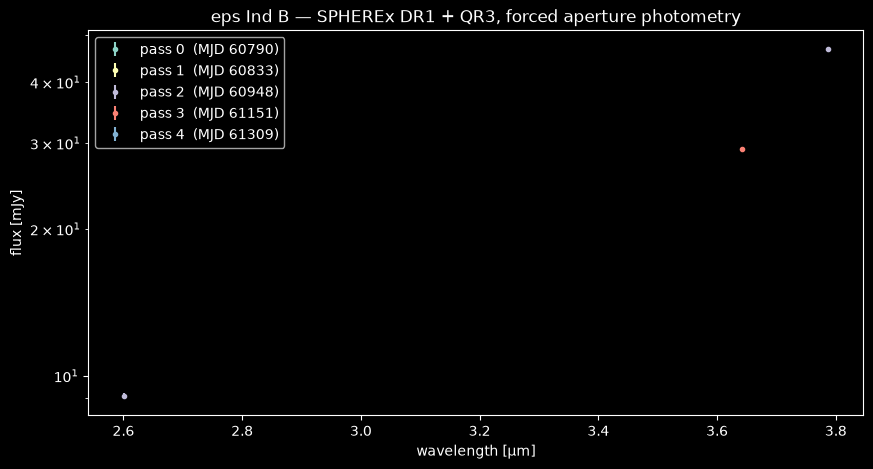

In [5]:
good = spec[spec["n_bad_ap"] == 0]  # drop measurements with a flagged pixel inside the aperture
fig, ax = plt.subplots(figsize=(10, 5))
for p in np.unique(good["pass_id"]):
    g = good[good["pass_id"] == p]
    ax.errorbar(g["lambda_um"], g["flux_mjy"], yerr=g["flux_err_mjy"], fmt="o", ms=3,
                label=f"pass {p}  (MJD {g['mjd'].min():.0f})")
ax.set_xlabel("wavelength [µm]")
ax.set_ylabel("flux [mJy]")
ax.set_yscale("log")
ax.set_title("eps Ind B — SPHEREx DR1 + QR3, forced aperture photometry")
ax.legend()
plt.show()


In [6]:
def combine(spec, by_pass=True):
    """Weighted mean of measurements closer than half a bandwidth in λ (per pass if by_pass)."""
    rows = []
    g = spec[spec["n_bad_ap"] == 0]
    for p in (np.unique(g["pass_id"]) if by_pass else [None]):
        s = g if p is None else g[g["pass_id"] == p]
        s = s[np.argsort(s["lambda_um"])]
        i = 0
        while i < len(s):
            j = i
            while j + 1 < len(s) and s["lambda_um"][j + 1] - s["lambda_um"][i] < 0.5 * s["bandwidth_um"][i]:
                j += 1
            b = s[i:j + 1]
            w = 1 / b["flux_err_mjy"] ** 2
            rows.append(dict(pass_id=-1 if p is None else int(p), lambda_um=float(np.average(b["lambda_um"], weights=w)),
                             flux_mjy=float(np.sum(w * b["flux_mjy"]) / w.sum()),
                             flux_err_mjy=float(1 / np.sqrt(w.sum())), n=len(b),
                             scatter_mjy=float(np.std(b["flux_mjy"])) if len(b) > 1 else np.nan))
            i = j + 1
    return Table(rows=rows)

per_pass = combine(spec)                 # one spectrum per pass (for variable stars like RW Aur)
all_passes = combine(spec, by_pass=False)  # one spectrum with everything (best S/N)
all_passes


pass_id,lambda_um,flux_mjy,flux_err_mjy,n,scatter_mjy
int64,float64,float64,float64,int64,float64
-1,nan,nan,nan,1,nan
-1,nan,nan,nan,1,nan
-1,nan,nan,nan,1,nan
-1,nan,nan,nan,1,nan
-1,nan,nan,nan,1,nan
-1,nan,nan,nan,1,nan
-1,nan,nan,nan,1,nan
-1,nan,nan,nan,1,nan
-1,nan,nan,nan,2,nan


24 frames sampled -> 23 measured
(<Column name='n_bad_ap' dtype='int64' length=6>
 0
 1
 6
11
15
19, array([18,  1,  1,  1,  1,  1]))


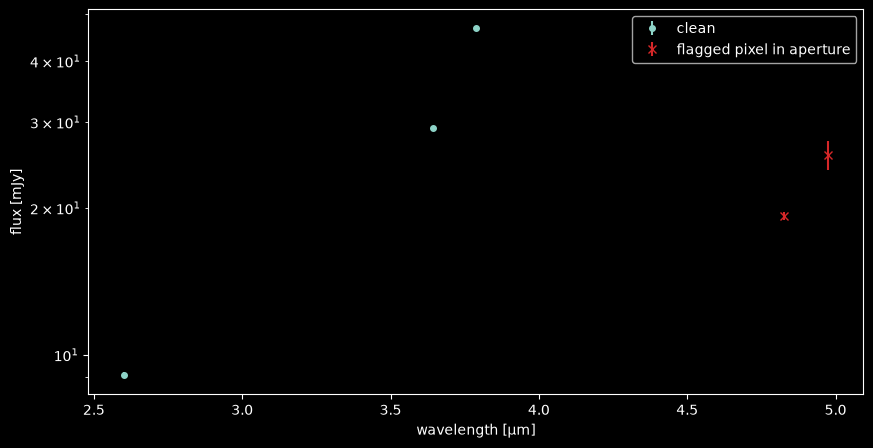

In [7]:
print(len(t[::20]), "frames sampled ->", len(spec), "measured")
print(np.unique(spec["n_bad_ap"], return_counts=True))
if "ap_flags" in spec.colnames:
    for det in np.unique(spec["detector"]):
        s = spec[spec["detector"] == det]
        print(f"D{det}:", list(zip(np.round(s["lambda_um"], 2), s["n_bad_ap"], s["ap_flags"])))

fig, ax = plt.subplots(figsize=(10, 5))
ok = spec["n_bad_ap"] == 0
ax.errorbar(spec["lambda_um"][ok], spec["flux_mjy"][ok], yerr=spec["flux_err_mjy"][ok], fmt="o", ms=4, label="clean")
ax.errorbar(spec["lambda_um"][~ok], spec["flux_mjy"][~ok], yerr=spec["flux_err_mjy"][~ok], fmt="x", ms=6,
            color="tab:red", label="flagged pixel in aperture")
ax.set_xlabel("wavelength [µm]"); ax.set_ylabel("flux [mJy]"); ax.set_yscale("log"); ax.legend()
plt.show()


In [8]:
f, b = np.array(spec["flux_mjy"]), np.array(spec["bkg_mjysr"])
for det in np.unique(spec["detector"]):
    m = spec["detector"] == det
    print(f"D{det}: n={m.sum():2d}  flux NaN={np.isnan(f[m]).sum():2d}  flux<=0={(f[m] <= 0).sum():2d}  "
          f"bkg NaN={np.isnan(b[m]).sum():2d}")


D1: n= 3  flux NaN= 3  flux<=0= 0  bkg NaN= 3
D2: n= 5  flux NaN= 5  flux<=0= 0  bkg NaN= 5
D3: n= 5  flux NaN= 5  flux<=0= 0  bkg NaN= 5
D4: n= 3  flux NaN= 0  flux<=0= 0  bkg NaN= 0
D5: n= 5  flux NaN= 5  flux<=0= 0  bkg NaN= 5
D6: n= 2  flux NaN= 0  flux<=0= 0  bkg NaN= 0


In [10]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from astropy import log
from astropy.table import Table
from astropy.stats import SigmaClip
from photutils.aperture import CircularAperture, CircularAnnulus, ApertureStats, aperture_photometry
import warnings

log.setLevel("WARNING")
R_AP_PIX, R_IN_PIX, R_OUT_PIX, HALF_PIX = 2.5, 6, 10, 12
# Official recipe. NOTE: SOURCE is NOT excluded from the background: in DR1 it covers ~45 % of each detector.
EXCLUDE = ["SUR_ERROR", "NONFUNC", "MISSING_DATA", "HOT", "COLD", "NONLINEAR",
           "PERSIST", "BLOOM", "SNOWBALL", "HALO", "SATELLITE_HALO"]


def measure(row):
    url = cfg.s3_https_base + json.loads(row["cloud_access"])["aws"]["key"]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        hd = fits.open(url, use_fsspec=True, lazy_load_hdus=True, fsspec_kwargs={"block_size": 2**20})
        hh = hd["IMAGE"].header
        x, y = map(float, WCS(hh).world_to_pixel(position_at(hh["MJD-AVG"])))
        if not (HALF_PIX <= x < 2040 - HALF_PIX and HALF_PIX <= y < 2040 - HALF_PIX):
            return None                                   # target at the detector edge
        wl = WCS(hh, fobj=hd, key="W"); wl.sip = None
        lam_um, bw_um = map(float, wl.pixel_to_world_values(x, y))
        r0, c0 = int(y) - HALF_PIX, int(x) - HALF_PIX
        sl = (slice(r0, r0 + 2 * HALF_PIX), slice(c0, c0 + 2 * HALF_PIX))
        img = hd["IMAGE"].section[sl].astype(float)
        var = hd["VARIANCE"].section[sl].astype(float)
        flags = hd["FLAGS"].section[sl].astype(np.int64)
        bits = {int(k[4:]): v for k, v in hd["FLAGS"].header.items() if k.startswith("MSKN")}
        mjy_per_mjysr = hh["OMEGA_MEDIAN"] * (u.arcsec**2).to(u.sr) * 1e9   # MJy/sr * sr -> mJy
        mjd = hh["MJD-AVG"]
        hd.close()

    pos = (x - c0, y - r0)
    ap = CircularAperture(pos, R_AP_PIX)
    an = CircularAnnulus(pos, R_IN_PIX, R_OUT_PIX)
    nonfinite = ~np.isfinite(img) | ~np.isfinite(var)
    bad = ((flags & sum(1 << b for b, n in bits.items() if n in EXCLUDE)) != 0) | nonfinite

    bkg = ApertureStats(img, an, mask=bad, sigma_clip=SigmaClip(sigma=3.0))   # neighbours removed by clipping
    ph = aperture_photometry(img - bkg.median, ap, error=np.sqrt(np.clip(var, 0, None)), mask=nonfinite)
    s = float(ph["aperture_sum"][0])
    s_err = float(np.hypot(ph["aperture_sum_err"][0], ap.area * bkg.std / np.sqrt(an.area)))

    return dict(mjd=mjd, pass_id=int(row["pass_id"]), detector=int(str(row["energy_bandpassname"])[-1]),
                lambda_um=lam_um, bandwidth_um=bw_um,
                flux_mjy=s * mjy_per_mjysr, flux_err_mjy=s_err * mjy_per_mjysr,
                n_bad_ap=int(ap.to_mask("center").multiply(bad.astype(int)).sum()))


def extract_spectrum(rows, workers=8):
    with ThreadPoolExecutor(workers) as ex:
        spec = Table(rows=[r for r in ex.map(measure, rows) if r])
    spec.sort("lambda_um")
    return spec


spec = extract_spectrum(t)          # ~6 min for 463 frames
print(len(spec), "measured")
out_dir = Path("../../../data"); out_dir.mkdir(exist_ok=True)
spec.write(out_dir / "eps_ind_b_spectrum.ecsv", overwrite=True)


454 measured


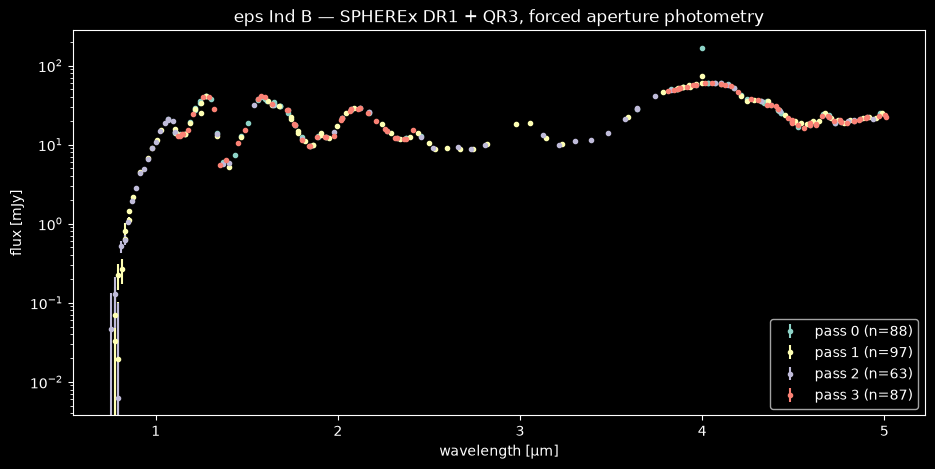

In [11]:
g = spec[(spec["n_bad_ap"] == 0) & np.isfinite(spec["flux_mjy"])]
fig, ax = plt.subplots(figsize=(11, 5))
for p in np.unique(g["pass_id"]):
    m = g["pass_id"] == p
    ax.errorbar(g["lambda_um"][m], g["flux_mjy"][m], g["flux_err_mjy"][m], fmt="o", ms=3,
                label=f"pass {p} (n={m.sum()})")
ax.set_yscale("log"); ax.set_xlabel("wavelength [µm]"); ax.set_ylabel("flux [mJy]")
ax.set_title("eps Ind B — SPHEREx DR1 + QR3, forced aperture photometry"); ax.legend()
plt.show()
